# 13 coins — data download (Binance.US)

Download klines with `python-binance` from Binance.US, keep the liquid coins, and save to disk. This defines the **13 coins** of the comparison universe (saved as `data/px_liquid_1h.pk`) and the Binance.US prices used in the Binance.US vs Binance global comparison. The Binance global prices of the same 13 coins come from `global30_data.ipynb`.


## 1. Download function (from HW8)

In [208]:
from binance.client import Client as bnb_client
from datetime import datetime
import pandas as pd
import numpy as np

# client = bnb_client()
### if you're in the US, use:
client = bnb_client(tld='US')

def get_binance_px(symbol, freq, start_ts='2020-01-01', end_ts='2025-12-31'):
    data = client.get_historical_klines(symbol, freq, start_ts, end_ts)
    columns = ['open_time','open','high','low','close','volume','close_time','quote_volume',
               'num_trades','taker_base_volume','taker_quote_volume','ignore']

    data = pd.DataFrame(data, columns=columns)

    # Convert from POSIX timestamp (number of millisecond since jan 1, 1970)
    data['open_time'] = pd.to_datetime(data['open_time'], unit='ms')
    data['close_time'] = pd.to_datetime(data['close_time'], unit='ms')
    return data

## 2. Download the universe

Compared with HW8, we use more coins and longer history, and we keep **volume** as well as close (we need volume for the activity / uninformed-trading ideas in the project).
Hourly bars give us flexibility: 4h or daily bars can be built later by resampling. The first run takes ~9 minutes; after that the saved files are loaded instead.

In [209]:
univ = ['BTCUSDT','ETHUSDT','BNBUSDT','XRPUSDT','ADAUSDT','SOLUSDT','DOGEUSDT',
        'DOTUSDT','AVAXUSDT','LINKUSDT','LTCUSDT','BCHUSDT','UNIUSDT','ATOMUSDT',
        'ETCUSDT','XLMUSDT','FILUSDT','ALGOUSDT','VETUSDT','MATICUSDT','AAVEUSDT',
        'NEARUSDT','MANAUSDT','HBARUSDT']

import os
freq = '1h'
px_file, vol_file = 'data/binanceus_1h_px.pk', 'data/binanceus_1h_vol.pk'

if os.path.exists(px_file):
    # already downloaded: just load it
    px = pd.read_pickle(px_file)
    vol = pd.read_pickle(vol_file)
else:
    px = {}
    vol = {}
    for x in univ:
        data = get_binance_px(x, freq)
        if len(data) == 0:
            print(x, 'no data')
            continue
        data = data.set_index('open_time')
        px[x] = data['close']
        vol[x] = data['quote_volume']       # volume in USDT
        print(x, len(data), data.index[0], '->', data.index[-1])

    px = pd.DataFrame(px).astype(float)
    vol = pd.DataFrame(vol).astype(float)
    px = px.reindex(pd.date_range(px.index[0], px.index[-1], freq=freq))
    vol = vol.reindex(px.index)

    os.makedirs('data', exist_ok=True)
    px.to_pickle(px_file)
    vol.to_pickle(vol_file)

print(px.shape)

(52585, 24)


## 3. Check the data

In [210]:
px.tail()

,BTCUSDT,ETHUSDT,BNBUSDT,XRPUSDT,ADAUSDT,SOLUSDT,DOGEUSDT,DOTUSDT,AVAXUSDT,LINKUSDT,...,ETCUSDT,XLMUSDT,FILUSDT,ALGOUSDT,VETUSDT,MATICUSDT,AAVEUSDT,NEARUSDT,MANAUSDT,HBARUSDT
2025-12-30 20:00:00,88134.78,2957.30,859.02,1.8675,0.3490,124.14,0.12311,1.816,12.52,12.39,...,11.91,0.2105,1.335,0.1145,0.01087,NaN,149.81,1.534,0.1189,0.11048
2025-12-30 21:00:00,88378.15,2967.84,858.48,1.8729,0.3506,123.99,0.12273,1.826,12.49,12.39,...,11.91,0.2105,1.335,0.1149,0.01080,NaN,151.02,1.534,0.1189,0.11062
2025-12-30 22:00:00,88318.24,2965.09,860.66,1.8731,0.3500,124.37,0.12273,1.807,12.56,12.40,...,11.76,0.2100,1.285,0.1131,0.01080,NaN,151.02,1.534,0.1179,0.11098
2025-12-30 23:00:00,88432.11,2974.59,859.87,1.8768,0.3515,124.99,0.12332,1.807,12.57,12.40,...,11.84,0.2111,1.329,0.1151,0.01083,NaN,151.02,1.534,0.1179,0.11179
2025-12-31 00:00:00,88415.90,2967.23,859.94,1.8742,0.3508,125.01,0.12326,1.810,12.51,12.38,...,11.79,0.2098,1.329,0.1140,0.01077,NaN,151.02,1.506,0.1185,0.11113


In [211]:
# when each coin starts/ends, how many bars are missing, and how liquid it is
summary = pd.DataFrame({
    'first': px.apply(lambda s: s.first_valid_index()),
    'last': px.apply(lambda s: s.last_valid_index()),
    'missing % (after first)': px.apply(lambda s: s[s.first_valid_index():].isna().mean() * 100),
    'median $vol/hour': vol.median(),
}).sort_values('median $vol/hour', ascending=False)
summary.round({'missing % (after first)': 1, 'median $vol/hour': 0})

,first,last,missing % (after first),median $vol/hour
BTCUSDT,2020-01-01 00:00:00,2025-12-31 00:00:00,0.1,147484.0
ETHUSDT,2020-01-01 00:00:00,2025-12-31 00:00:00,0.1,54508.0
SOLUSDT,2020-09-18 13:00:00,2025-12-31 00:00:00,0.0,25514.0
ADAUSDT,2020-01-01 00:00:00,2025-12-31 00:00:00,0.1,10584.0
BNBUSDT,2020-01-01 00:00:00,2025-12-31 00:00:00,0.1,8820.0
DOGEUSDT,2020-01-01 00:00:00,2025-12-31 00:00:00,0.1,7984.0
XRPUSDT,2020-01-01 00:00:00,2025-12-31 00:00:00,41.7,5702.0
VETUSDT,2020-01-01 00:00:00,2025-12-31 00:00:00,0.1,4200.0
MATICUSDT,2022-01-05 01:00:00,2025-01-10 01:00:00,24.4,3470.0
LTCUSDT,2020-01-01 00:00:00,2025-12-31 00:00:00,0.1,3021.0


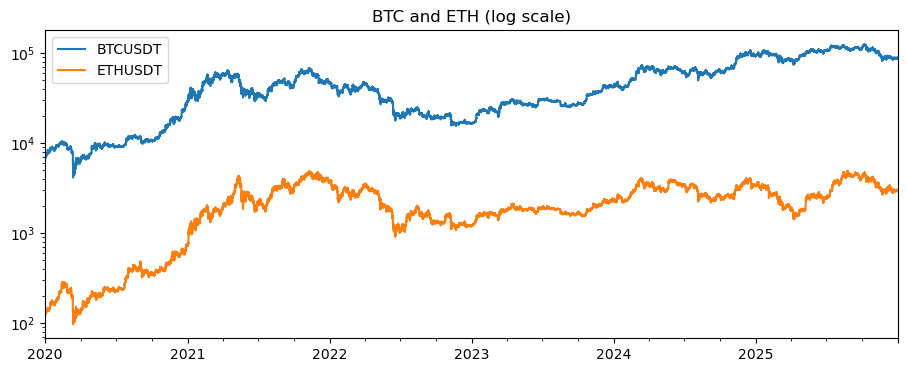

In [212]:
px[['BTCUSDT', 'ETHUSDT']].plot(logy=True, figsize=(11, 4), title='BTC and ETH (log scale)');

In [213]:
ret = px.pct_change(fill_method=None)
ret.describe().T[['count', 'mean', 'std', 'min', 'max']].round(4)

,count,mean,std,min,max
BTCUSDT,52537.0,0.0001,0.0067,-0.1751,0.1775
ETHUSDT,52537.0,0.0001,0.0086,-0.2140,0.1555
BNBUSDT,52537.0,0.0001,0.0089,-0.2038,0.1488
XRPUSDT,30666.0,0.0001,0.0103,-0.1542,0.2764
ADAUSDT,52537.0,0.0001,0.0112,-0.2136,0.3305
SOLUSDT,46287.0,0.0002,0.0131,-0.1966,0.1691
DOGEUSDT,52537.0,0.0002,0.0142,-0.2505,0.6171
DOTUSDT,35739.0,-0.0000,0.0098,-0.1912,0.2102
AVAXUSDT,36075.0,0.0000,0.0111,-0.2537,0.2423
LINKUSDT,34719.0,0.0000,0.0100,-0.1399,0.1344


## 4. Keep only liquid coins

Binance.US volume is thin for many coins (some trade only a few hundred dollars per hour). Illiquid coins have stale prices that sit flat for hours and then jump, which creates **fake reversal** in a backtest.

Rule: keep coins whose **median hourly volume is at least $1,000**.

Caveat: this uses the full-sample median, which is a mild look-ahead. A stricter point-in-time version (filtering on trailing volume at each date) can be added in a later step.

In [214]:
MIN_VOL = 1000      # USDT per hour
liquid = summary.index[summary['median $vol/hour'] >= MIN_VOL].tolist()

# also drop coins with big gaps: XRP (delisted from Binance.US for ~2 years), MATIC (ends Jan-2025)
gappy = ['XRPUSDT', 'MATICUSDT']
keep = [x for x in liquid if x not in gappy]
dropped = [x for x in px.columns if x not in keep]

print(len(keep), 'coins kept:', keep)
print(len(dropped), 'dropped:', dropped)

13 coins kept: ['BTCUSDT', 'ETHUSDT', 'SOLUSDT', 'ADAUSDT', 'BNBUSDT', 'DOGEUSDT', 'VETUSDT', 'LTCUSDT', 'AVAXUSDT', 'ATOMUSDT', 'XLMUSDT', 'LINKUSDT', 'HBARUSDT']
11 dropped: ['XRPUSDT', 'DOTUSDT', 'BCHUSDT', 'UNIUSDT', 'ETCUSDT', 'FILUSDT', 'ALGOUSDT', 'MATICUSDT', 'AAVEUSDT', 'NEARUSDT', 'MANAUSDT']


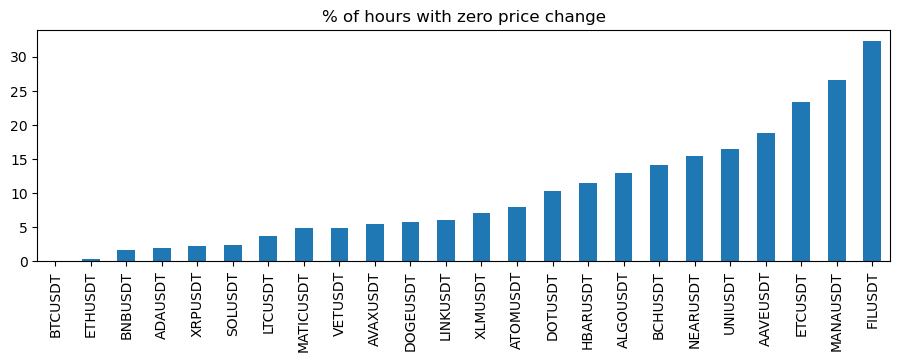

In [215]:
# illiquid coins have many hours with zero price change (stale prices)
stale = (ret == 0).where(px.notna()).mean().sort_values() * 100
stale.round(1).plot(kind='bar', figsize=(11, 3), title='% of hours with zero price change');

We also drop **XRP** and **MATIC**: they are liquid, but have large gaps (XRP was delisted from Binance.US for part of the period, 42% of hours missing; MATIC stops in Jan-2025).

## 5. select the liquid universe

In [216]:
px = px[keep]
vol = vol[keep]
print(px.shape, vol.shape)

px.to_pickle('data/px_liquid_1h.pk')
vol.to_pickle('data/vol_liquid_1h.pk')
ret = px.pct_change(fill_method=None)
# later steps load them with:
# px = pd.read_pickle('data/px_liquid_1h.pk')
# vol = pd.read_pickle('data/vol_liquid_1h.pk')

(52585, 13) (52585, 13)


In [217]:
summary = pd.DataFrame({
    'first': px.apply(lambda s: s.first_valid_index()),
    'last': px.apply(lambda s: s.last_valid_index()),
    'missing % (after first)': px.apply(lambda s: s[s.first_valid_index():].isna().mean() * 100),
    'median $vol/hour': vol.median(),
}).sort_values('median $vol/hour', ascending=False)
summary.round({'missing % (after first)': 1, 'median $vol/hour': 0})

,first,last,missing % (after first),median $vol/hour
BTCUSDT,2020-01-01 00:00:00,2025-12-31,0.1,147484.0
ETHUSDT,2020-01-01 00:00:00,2025-12-31,0.1,54508.0
SOLUSDT,2020-09-18 13:00:00,2025-12-31,0.0,25514.0
ADAUSDT,2020-01-01 00:00:00,2025-12-31,0.1,10584.0
BNBUSDT,2020-01-01 00:00:00,2025-12-31,0.1,8820.0
DOGEUSDT,2020-01-01 00:00:00,2025-12-31,0.1,7984.0
VETUSDT,2020-01-01 00:00:00,2025-12-31,0.1,4200.0
LTCUSDT,2020-01-01 00:00:00,2025-12-31,0.1,3021.0
AVAXUSDT,2021-11-18 13:00:00,2025-12-31,0.0,2625.0
ATOMUSDT,2020-01-01 00:00:00,2025-12-31,0.1,1429.0


<Axes: >

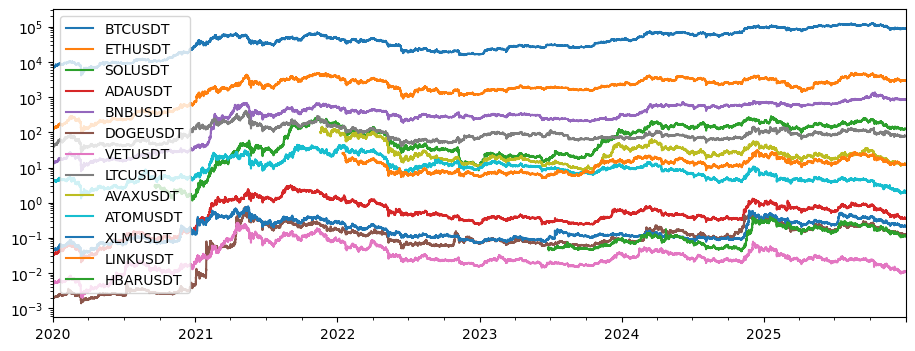

In [218]:
px.plot(logy=True, figsize=(11, 4))

## 6. Extend the data to Oct-2026

The data above stops at 2025-12-31. The **same 13 coins** are extended to Oct-2026 and saved to separate files (re-selecting coins with 2026 volume would use future information).


In [ ]:
# download 2026 for the same 13 coins and append to the existing data
px_full_file, vol_full_file = 'data/px_liquid_1h_full.pk', 'data/vol_liquid_1h_full.pk'
NEW_START, NEW_END = '2025-12-31', '2026-10-18'

if os.path.exists(px_full_file):
    px_full = pd.read_pickle(px_full_file)
    vol_full = pd.read_pickle(vol_full_file)
else:
    px_new, vol_new = {}, {}
    for x in keep:                                     # same universe as above
        data = get_binance_px(x, freq, start_ts=NEW_START, end_ts=NEW_END).set_index('open_time')
        px_new[x] = data['close']
        vol_new[x] = data['quote_volume']
    px_new = pd.DataFrame(px_new).astype(float)
    vol_new = pd.DataFrame(vol_new).astype(float)

    # old data first; the overlapping bar (2025-12-31 00:00) is kept from the old file
    px_full = pd.concat([px[keep], px_new])
    vol_full = pd.concat([vol[keep], vol_new])
    px_full = px_full[~px_full.index.duplicated(keep='first')]
    vol_full = vol_full[~vol_full.index.duplicated(keep='first')]
    full_index = pd.date_range(px_full.index[0], px_full.index[-1], freq=freq)
    px_full, vol_full = px_full.reindex(full_index), vol_full.reindex(full_index)

    px_full.to_pickle(px_full_file)
    vol_full.to_pickle(vol_full_file)

print(px_full.shape, px_full.index[0], '->', px_full.index[-1])
print('missing % in 2026:', (px_full.loc['2026'].isna().mean()*100).round(2).to_dict())